<a href="https://colab.research.google.com/github/LetheeshBalaji/DEEP-LEARNING/blob/main/24BAD063_Exp_7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import tensorflow as tf
from tensorflow.keras import layers
import numpy as np
import matplotlib.pyplot as plt

# Load MNIST dataset
(x_train, _), (_, _) = tf.keras.datasets.mnist.load_data()

# Normalize images
x_train = (x_train.astype("float32") - 127.5) / 127.5
x_train = np.expand_dims(x_train, axis=-1)

noise_dim = 100

In [3]:
# Generator
generator = tf.keras.Sequential([
    layers.Dense(256, input_shape=(noise_dim,)),
    layers.LeakyReLU(negative_slope=0.2),
    layers.BatchNormalization(),

    layers.Dense(512),
    layers.LeakyReLU(negative_slope=0.2),
    layers.BatchNormalization(),

    layers.Dense(784, activation='tanh'),
    layers.Reshape((28, 28, 1))
])

# Discriminator
discriminator = tf.keras.Sequential([
    layers.Flatten(input_shape=(28, 28, 1)),
    layers.Dense(512),
    layers.LeakyReLU(negative_slope=0.2),

    layers.Dense(256),
    layers.LeakyReLU(negative_slope=0.2),

    layers.Dense(1, activation='sigmoid')
])

generator.summary()
discriminator.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 256)            │        25,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_4 (LeakyReLU)       │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 512)            │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_5 (LeakyReLU)       │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 784)            │       402,192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_1 (Reshape)             │ (None, 28, 28, 1)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 562,704 (2.15 MB)

 Trainable params: 561,168 (2.14 MB)

 Non-trainable params: 1,536 (6.00 KB)

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_6 (LeakyReLU)       │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_7 (LeakyReLU)       │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 533,505 (2.04 MB)

 Trainable params: 533,505 (2.04 MB)

 Non-trainable params: 0 (0.00 B)

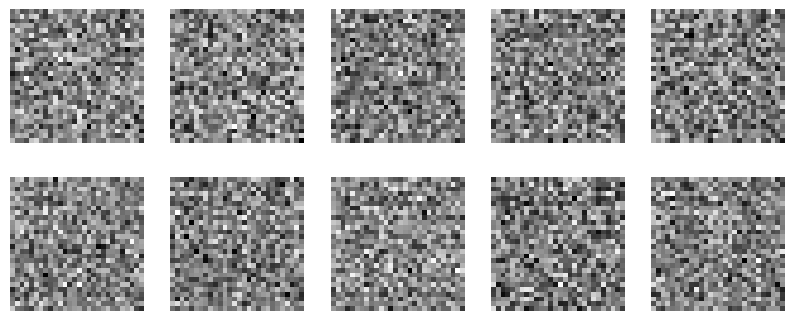

In [4]:
# Generate random noise
noise = tf.random.normal([10, noise_dim])

# Generate fake images
fake_images = generator(noise, training=False)

# Display images
plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(fake_images[i, :, :, 0] * 0.5 + 0.5,
               cmap='gray')
    plt.axis('off')

plt.show()

In [5]:
# Loss function and optimizers
loss_fn = tf.keras.losses.BinaryCrossentropy()

g_optimizer = tf.keras.optimizers.Adam(0.0002)
d_optimizer = tf.keras.optimizers.Adam(0.0002)

# Training function
@tf.function
def train_step(real_images):

    batch_size = tf.shape(real_images)[0]
    noise = tf.random.normal([batch_size, noise_dim])

    with tf.GradientTape() as g_tape, \
         tf.GradientTape() as d_tape:

        fake_images = generator(noise, training=True)

        real_output = discriminator(real_images, training=True)
        fake_output = discriminator(fake_images, training=True)

        # Generator tries to fool discriminator
        g_loss = loss_fn(
            tf.ones_like(fake_output), fake_output
        )

        # Discriminator identifies real and fake
        d_loss_real = loss_fn(
            tf.ones_like(real_output), real_output
        )

        d_loss_fake = loss_fn(
            tf.zeros_like(fake_output), fake_output
        )

        d_loss = d_loss_real + d_loss_fake

    # Calculate gradients
    g_gradients = g_tape.gradient(
        g_loss, generator.trainable_variables
    )

    d_gradients = d_tape.gradient(
        d_loss, discriminator.trainable_variables
    )

    # Update weights
    g_optimizer.apply_gradients(
        zip(g_gradients, generator.trainable_variables)
    )

    d_optimizer.apply_gradients(
        zip(d_gradients, discriminator.trainable_variables)
    )

    return g_loss, d_loss


# Train GAN
for epoch in range(10):

    for i in range(0, len(x_train), 128):
        real_images = x_train[i:i+128]
        g_loss, d_loss = train_step(real_images)

    print("Epoch:", epoch+1,
          "Generator Loss:", float(g_loss),
          "Discriminator Loss:", float(d_loss))

Epoch: 1 Generator Loss: 7.651679992675781 Discriminator Loss: 0.008182051591575146
Epoch: 2 Generator Loss: 5.184572696685791 Discriminator Loss: 0.2615130841732025
Epoch: 3 Generator Loss: 4.89324951171875 Discriminator Loss: 0.5272813439369202
Epoch: 4 Generator Loss: 2.9286205768585205 Discriminator Loss: 0.46292415261268616
Epoch: 5 Generator Loss: 3.459146499633789 Discriminator Loss: 0.8215131759643555
Epoch: 6 Generator Loss: 2.1376397609710693 Discriminator Loss: 1.0508439540863037
Epoch: 7 Generator Loss: 2.7761833667755127 Discriminator Loss: 1.2197705507278442
Epoch: 8 Generator Loss: 3.1677703857421875 Discriminator Loss: 1.0076708793640137
Epoch: 9 Generator Loss: 1.965197205543518 Discriminator Loss: 0.7879915237426758
Epoch: 10 Generator Loss: 1.927946925163269 Discriminator Loss: 1.0369330644607544


In [6]:
# Generate fake images
noise = tf.random.normal([128, noise_dim])
fake_images = generator(noise, training=False)

# Get discriminator predictions
real_output = discriminator(x_train[:128], training=False)
fake_output = discriminator(fake_images, training=False)

# Calculate losses
g_loss = loss_fn(
    tf.ones_like(fake_output), fake_output
)

d_loss_real = loss_fn(
    tf.ones_like(real_output), real_output
)

d_loss_fake = loss_fn(
    tf.zeros_like(fake_output), fake_output
)

d_loss = d_loss_real + d_loss_fake

print("Generator Loss:", float(g_loss))
print("Discriminator Loss:", float(d_loss))

Generator Loss: 1.2771868705749512
Discriminator Loss: 1.1069707870483398
